# Analyzing Airport Networks — Participant 6: Communities and Synthesis

**Question:** What groups does the airport network contain, and what should the organisation take away?

**Graph-theory topics:** graph partitions and communities; modularity; edge betweenness;
hierarchical splitting (Girvan–Newman); comparing partitions (ARI / NMI).

*How to run:* put `routes.dat` and `airports.dat` from OpenFlights in a `data/` folder next to this
notebook, then **Restart & Run All**. Requires `pandas`, `numpy`, `networkx`, `matplotlib`, `scikit-learn`.

**Graph model (shared with the group):** vertices = airports (IATA codes) in `routes.dat`; an edge =
at least one listed direct route between two airports in either direction. Undirected and simple
(no duplicates, no self-loops). `records` = number of route rows for the pair — **not** flight frequency.

In [3]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import time

DATA = "../data"
SEED = 42

## Build the graph

In [4]:
route_cols = ["airline", "airline_id", "src", "src_id", "dst", "dst_id", "codeshare", "stops", "equipment"]
airport_cols = ["airport_id", "name", "city", "country", "iata", "icao", "lat", "lon", "altitude",
                "utc_offset", "dst_rule", "tz", "type", "source"]
routes = pd.read_csv(f"{DATA}/routes.dat", header=None, names=route_cols, na_values="\\N", keep_default_na=False)
airports = pd.read_csv(f"{DATA}/airports.dat", header=None, names=airport_cols, na_values="\\N", keep_default_na=False)

r = routes.dropna(subset=["src", "dst"])
r = r[r["src"] != r["dst"]]                                   # drop self-loops
pair_counts = Counter(tuple(sorted(p)) for p in zip(r["src"], r["dst"]))

G_full = nx.Graph()
for (a, b), n in pair_counts.items():
    G_full.add_edge(a, b, records=n)

ap = airports.dropna(subset=["iata"]).drop_duplicates("iata").set_index("iata")
nx.set_node_attributes(G_full, ap["name"].to_dict(), "name")
nx.set_node_attributes(G_full, ap["country"].to_dict(), "country")
print(f"Graph: {G_full.number_of_nodes():,} airports, {G_full.number_of_edges():,} edges")

Graph: 3,425 airports, 19,256 edges


---
## 6.0 Work on the largest connected component
Community detection runs on the **largest connected component** (communities are only meaningful
where paths exist). Agree this choice with Participant 4.

In [5]:
def ordered_subgraph(src, nodes):
    """Induced subgraph with nodes/edges in sorted order, so Louvain results are reproducible
    (plain .subgraph() inherits Python set ordering, which changes between runs)."""
    keep = set(nodes)
    H = nx.Graph()
    H.add_nodes_from((n, src.nodes[n]) for n in sorted(keep))
    H.add_edges_from(sorted((min(u, v), max(u, v), d) for u, v, d in src.edges(keep, data=True)
                            if u in keep and v in keep))
    return H

largest = max(nx.connected_components(G_full), key=len)
G = ordered_subgraph(G_full, largest)
print(f"Components: {nx.number_connected_components(G_full)} | largest has "
      f"{G.number_of_nodes():,} airports, {G.number_of_edges():,} edges")

Components: 8 | largest has 3,397 airports, 19,230 edges


## 6.1 Louvain on the whole network
*Plain language:* Louvain repeatedly moves airports between groups to maximise **modularity** —
"more connections inside groups than you'd expect by chance". Score ranges roughly −0.5 to 1;
above ~0.3 usually signals real group structure.

Run it **unweighted** (our main model) and **weighted by route records** (sensitivity check).
Louvain has randomness, so we also check stability across seeds.

In [ ]:
lv = nx.community.louvain_communities(G, weight=None, seed=SEED)
lv_w = nx.community.louvain_communities(G, weight="records", seed=SEED)
print(f"Unweighted Louvain: {len(lv)} communities, modularity = {nx.community.modularity(G, lv):.3f}") #each link is worth 1
print(f"Weighted Louvain:   {len(lv_w)} communities, modularity = {nx.community.modularity(G, lv_w, weight='records'):.3f}")

def labels(partition, nodes):
    m = {v: i for i, c in enumerate(partition) for v in c}
    return [m[v] for v in nodes]

nodes = list(G)
print(f"Agreement unweighted vs weighted: ARI = {adjusted_rand_score(labels(lv, nodes), labels(lv_w, nodes)):.3f}, "
      f"NMI = {normalized_mutual_info_score(labels(lv, nodes), labels(lv_w, nodes)):.3f}")

# Stability across random seeds
runs = [nx.community.louvain_communities(G, seed=s) for s in range(5)]
aris = [adjusted_rand_score(labels(runs[0], nodes), labels(p, nodes)) for p in runs[1:]]
print("ARI of seed 0 vs seeds 1-4:", np.round(aris, 3))

Unweighted Louvain: 23 communities, modularity = 0.665
Weighted Louvain:   19 communities, modularity = 0.657
Agreement unweighted vs weighted: ARI = 0.807, NMI = 0.871
ARI of seed 0 vs seeds 1-4: [0.721 0.743 0.734 0.773]


## 6.2 Describe the biggest Louvain communities (make them interpretable)
Community IDs are arbitrary. We describe each group by its **top countries** and **highest-degree airports**.

In [8]:
deg = dict(G.degree())
rows = []
for c in sorted(lv, key=len, reverse=True)[:10]:
    top_countries = Counter(G.nodes[v].get("country", "(not in airports.dat)") for v in c).most_common(3)
    hubs = sorted(c, key=deg.get, reverse=True)[:5]
    rows.append({"size": len(c),
                 "top countries": ", ".join(f"{k} ({n})" for k, n in top_countries),
                 "biggest airports": ", ".join(hubs)})
pd.DataFrame(rows)

,size,top countries,biggest airports
0,699,"United States (410), Canada (92), Mexico (57)","ATL, ORD, DFW, DEN, IAH"
1,527,"France (54), United Kingdom (45), Spain (40)","AMS, FRA, CDG, MUC, LHR"
2,504,"China (174), Indonesia (64), Japan (62)","PEK, PVG, CAN, HKG, ICN"
3,488,"India (71), Iran (43), Turkey (32)","IST, DXB, DOH, JED, DEL"
4,284,"Brazil (124), Colombia (48), Argentina (36)","GRU, BOG, LIM, VCP, GIG"
5,244,"Australia (112), Vanuatu (27), New Zealand (25)","SYD, BNE, MEL, AKL, PER"
6,183,"United States (132), (not in airports.dat) (51)","ANC, BET, FAI, OME, JNU"
7,170,"Russia (112), Kazakhstan (17), Uzbekistan (11)","DME, SVO, LED, VKO, SVX"
8,76,Canada (76),"YZF, YRT, YFB, YVP, YGW"
9,52,"(not in airports.dat) (28), Greenland (20), Ic...","GOH, JUV, SFJ, JJU, UMD"


## 6.3 Where do the central airports fall?
Here: top 15 by degree and by betweenness (approximate
betweenness with k samples to keep it fast).
A **bridge-like** airport has many neighbours *outside* its own community.

In [6]:
btw = nx.betweenness_centrality(G, k=500, seed=SEED)
comm_of = {v: i for i, c in enumerate(lv) for v in c}
central = sorted(set(sorted(deg, key=deg.get, reverse=True)[:15]) | set(sorted(btw, key=btw.get, reverse=True)[:15]),
                 key=deg.get, reverse=True)
rows = []
for v in central:
    nb = list(G[v])
    outside = sum(comm_of[u] != comm_of[v] for u in nb) / len(nb)
    rows.append({"airport": v, "name": G.nodes[v].get("name"), "degree": deg[v],
                 "betweenness": round(btw[v], 4), "community size": len(lv[comm_of[v]]),
                 "share of neighbours in other communities": round(outside, 2)})
central_df = pd.DataFrame(rows)
central_df

,airport,name,degree,betweenness,community size,share of neighbours in other communities
0,AMS,Amsterdam Airport Schiphol,248,0.0480,527,0.35
1,FRA,Frankfurt am Main Airport,244,0.0522,527,0.45
2,CDG,Charles de Gaulle International Airport,240,0.0609,527,0.46
3,IST,Istanbul Airport,236,0.0447,488,0.58
4,ATL,Hartsfield Jackson Atlanta International Airport,217,0.0285,699,0.12
5,PEK,Beijing Capital International Airport,207,0.0507,504,0.31
6,ORD,Chicago O'Hare International Airport,206,0.0525,699,0.14
7,MUC,Munich Airport,192,0.0139,527,0.24
8,DME,Domodedovo International Airport,190,0.0254,170,0.40
9,DFW,Dallas Fort Worth International Airport,188,0.0259,699,0.09


## 6.4 Girvan–Newman on a smaller subgraph
*Plain language:* Girvan–Newman repeatedly deletes the edge that the most shortest paths run through
(highest **edge betweenness**) — usually the bridges between groups — until the network splits.
It is far too slow for the full network (edge betweenness is recomputed after every deletion),
so we compare both methods on **one country's domestic network**. State this limitation explicitly.

In [9]:
COUNTRY = "Australia"   # try "India", "Brazil", "Indonesia", "Canada"
dom = [v for v in G_full if G_full.nodes[v].get("country") == COUNTRY]
H = G_full.subgraph(dom)
H = ordered_subgraph(G_full, max(nx.connected_components(H), key=len))
print(f"{COUNTRY} domestic network: {H.number_of_nodes()} airports, {H.number_of_edges()} edges")

t = time.time()
best, best_q, history = None, -1, []
for level, part in enumerate(nx.community.girvan_newman(H)):
    q = nx.community.modularity(H, part)
    history.append((len(part), q))
    if q > best_q:
        best, best_q = part, q
    if len(part) >= 40:   # stop well past the modularity peak
        break
gn = [set(c) for c in best]
print(f"Girvan-Newman best split: {len(gn)} communities, modularity = {best_q:.3f}  ({time.time()-t:.1f}s)")

lv_H = nx.community.louvain_communities(H, seed=SEED)
print(f"Louvain on same subgraph: {len(lv_H)} communities, modularity = {nx.community.modularity(H, lv_H):.3f}")

hn = list(H)
print(f"Agreement GN vs Louvain: ARI = {adjusted_rand_score(labels(gn, hn), labels(lv_H, hn)):.3f}, "
      f"NMI = {normalized_mutual_info_score(labels(gn, hn), labels(lv_H, hn)):.3f}")

Australia domestic network: 113 airports, 227 edges
Girvan-Newman best split: 17 communities, modularity = 0.409  (0.9s)
Louvain on same subgraph: 8 communities, modularity = 0.466
Agreement GN vs Louvain: ARI = 0.458, NMI = 0.709


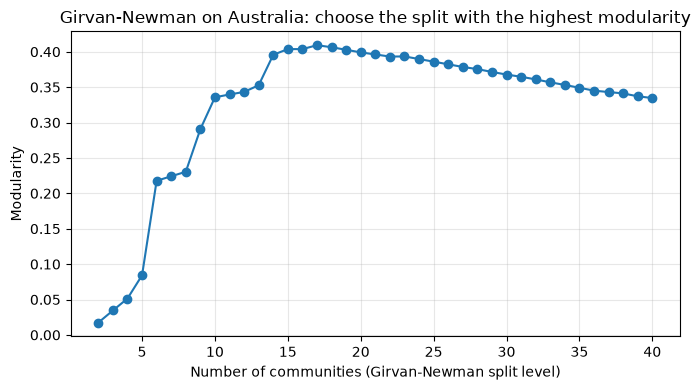

In [10]:
k, q = zip(*history)
plt.figure(figsize=(7, 4))
plt.plot(k, q, marker="o")
plt.xlabel("Number of communities (Girvan-Newman split level)")
plt.ylabel("Modularity")
plt.title(f"Girvan-Newman on {COUNTRY}: choose the split with the highest modularity")
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("fig_gn_modularity.png", dpi=150)
plt.show()

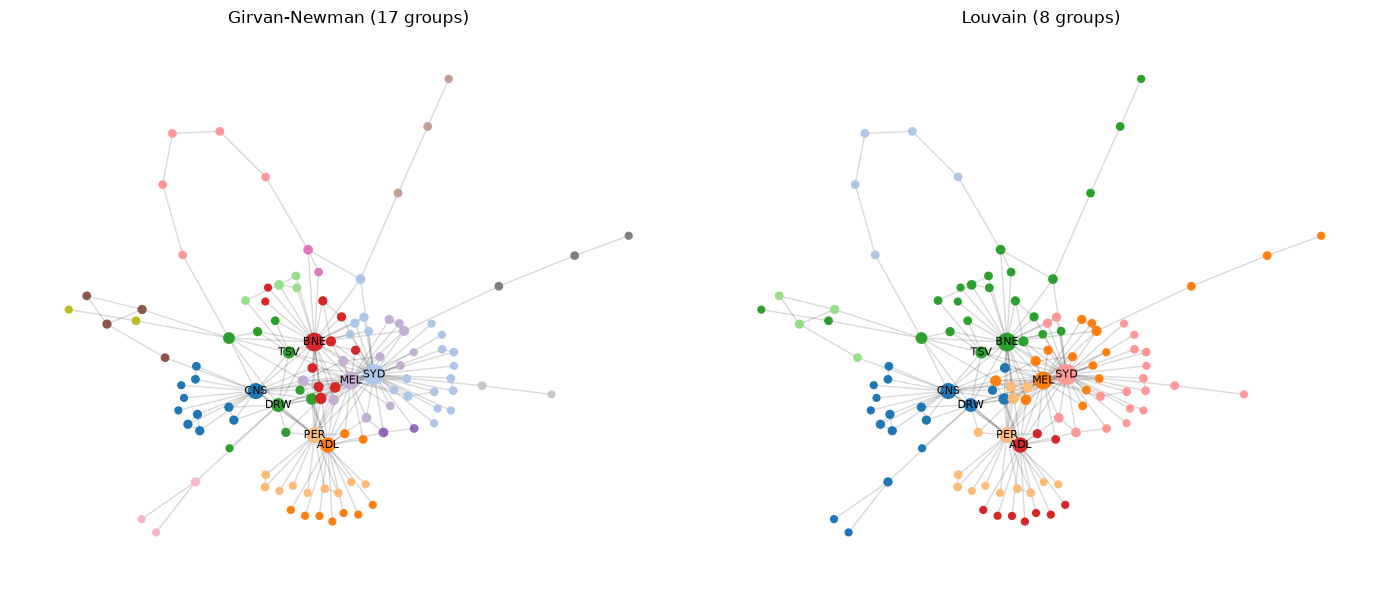

In [11]:
def show(part, title, ax):
    pos = nx.spring_layout(H, seed=SEED)
    cmap = plt.get_cmap("tab20")
    cid = {v: i for i, c in enumerate(part) for v in c}
    nx.draw_networkx_edges(H, pos, alpha=0.15, ax=ax)
    nx.draw_networkx_nodes(H, pos, node_color=[cmap(cid[v] % 20) for v in H],
                           node_size=[20 + 4 * H.degree(v) for v in H], ax=ax)
    top = sorted(H, key=H.degree, reverse=True)[:8]
    nx.draw_networkx_labels(H, pos, {v: v for v in top}, font_size=8, ax=ax)
    ax.set_title(title); ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
show(gn, f"Girvan-Newman ({len(gn)} groups)", axes[0])
show(lv_H, f"Louvain ({len(lv_H)} groups)", axes[1])
plt.tight_layout(); plt.savefig("fig_gn_vs_louvain.png", dpi=150); plt.show()

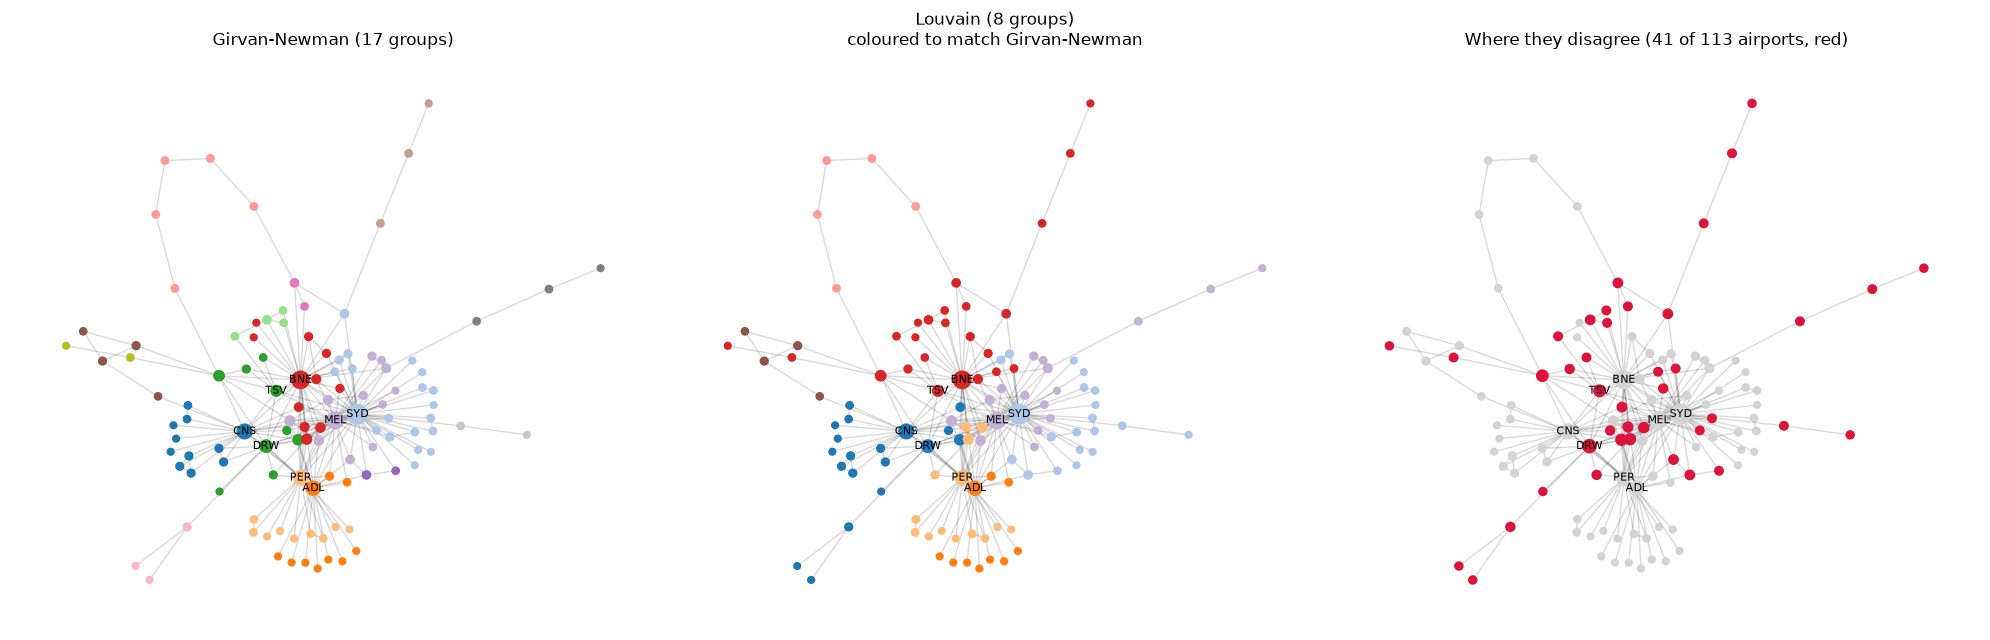

41 of 113 airports are grouped differently.


In [12]:
# --- Compare Girvan-Newman and Louvain with matched colours ---
cmap = plt.get_cmap("tab20")
pos = nx.spring_layout(H, seed=SEED)
gn_id = {v: i for i, c in enumerate(gn) for v in c}

# Give each Louvain group the colour of the Girvan-Newman group it overlaps most
lv_colour = {}
for c in lv_H:
    best_gn = Counter(gn_id[v] for v in c).most_common(1)[0][0]
    for v in c:
        lv_colour[v] = best_gn

# An airport "disagrees" if its Louvain group is not mainly its own Girvan-Newman group
disagree = [v for v in H if lv_colour[v] != gn_id[v]]

def draw(colour_of, title, ax, highlight=None):
    nx.draw_networkx_edges(H, pos, alpha=0.15, ax=ax)
    if highlight is None:
        nx.draw_networkx_nodes(H, pos, node_color=[cmap(colour_of[v] % 20) for v in H],
                               node_size=[20 + 4 * H.degree(v) for v in H], ax=ax)
    else:
        nx.draw_networkx_nodes(H, pos, node_color="lightgrey",
                               node_size=[20 + 4 * H.degree(v) for v in H], ax=ax)
        nx.draw_networkx_nodes(H, pos, nodelist=highlight, node_color="crimson",
                               node_size=[30 + 4 * H.degree(v) for v in highlight], ax=ax)
    top = sorted(H, key=H.degree, reverse=True)[:8]
    nx.draw_networkx_labels(H, pos, {v: v for v in top}, font_size=8, ax=ax)
    ax.set_title(title); ax.axis("off")

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
draw(gn_id, f"Girvan-Newman ({len(gn)} groups)", axes[0])
draw(lv_colour, f"Louvain ({len(lv_H)} groups)\ncoloured to match Girvan-Newman", axes[1])
draw(None, f"Where they disagree ({len(disagree)} of {H.number_of_nodes()} airports, red)",
     axes[2], highlight=disagree)
plt.tight_layout(); plt.savefig("fig_gn_vs_louvain.png", dpi=150); plt.show()
print(f"{len(disagree)} of {H.number_of_nodes()} airports are grouped differently.")

## 6.5 Synthesis

### What the organisation should take away

1. **The network is strongly regional.** There are **23 communities** with a modularity of **0.665**, and they match world regions. Most connections stay inside a region.
2. **A few bridge hubs hold the regions together.** Airports such as **Istanbul (IST)** and **London Heathrow (LHR)** link many communities, so disruption at these hubs would affect connections *between* regions, not just within one.
3. **Some remote areas hang on a single hub.** **Anchorage (ANC)** for Alaska is one example, and Girvan–Newman's small chains in Australia are another. Losing that hub could cut these airports off.

### Recommendation

Prioritise resilience planning, such as backup routing and capacity, at **bridge hubs** and **single-hub dependencies**, not only at the airports with the most connections.

### Limitations

- Only 2014 listed routes are used.
- No flight frequencies, passenger numbers or capacity.
- Louvain involves randomness (results vary slightly between runs; we fixed `SEED = 42`).
- Girvan–Newman was only run on one country (Australia) because it is too slow for the full network.

### Future work

- Add schedule or passenger data as edge weights.
- Analyse the directed graph.
- Compare individual airlines using `airlines.dat`.
- Track how the network changes over time.